# 06 — Fusión de Canales EMG

Este notebook combina la información de los 8 canales en una sola variable por feature y compara
varias estrategias de fusión según la separabilidad entre agarres (η²).

El dataset de entrada ya viene transformado (Box-Cox) y normalizado, así que aquí no se vuelve a normalizar.
El reposo (`stimulus = 0`) se excluye.

**Pipeline:**
1. Carga de datos
2. η² baseline (canales individuales, sin fusión)
3. Funciones de fusión (5 métodos: `mean`, `median`, `wmean`, `max`, `std`)
4. η² de cada método de fusión
5. Tabla resumen y selección del mejor método por feature
6. Construcción del dataset fusionado
7. Verificación final

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.lines as mlines

sns.set_style('whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

FEATURES = ['VAR_STD', 'Range', 'Energy', 'Peak_to_Peak', 'VAR', 'Max', 'MNF', 'SSC']
N_CHANNELS = 8

## 1. Carga de datos

In [3]:
ruta='../data/master/intact_bc_mean.csv'

In [4]:
df = pd.read_csv(ruta)
df=df[df['stimulus']!=0]
meta_cols = ['origin_db', 'subject', 'stimulus']
signal_cols = [f'Channel {ch}_{feat}' for ch in range(1, N_CHANNELS + 1) for feat in FEATURES]

print(f'Shape: {df.shape}')
print(f'Sujetos (subject + origin_db): {(df["subject"].astype(str) + "_" + df["origin_db"].astype(str)).nunique()}')
print(f'Estímulos: {sorted(df["stimulus"].unique())}')
print(f'Columnas de señal: {len(signal_cols)}')
df.head()

Shape: (609, 67)
Sujetos (subject + origin_db): 87
Estímulos: [np.int64(22), np.int64(25), np.int64(27), np.int64(30), np.int64(31), np.int64(37), np.int64(40)]
Columnas de señal: 64


,origin_db,subject,stimulus,Channel 1_VAR_STD,Channel 2_VAR_STD,Channel 3_VAR_STD,Channel 4_VAR_STD,Channel 5_VAR_STD,Channel 6_VAR_STD,Channel 7_VAR_STD,...,Channel 7_MNF,Channel 8_MNF,Channel 1_SSC,Channel 2_SSC,Channel 3_SSC,Channel 4_SSC,Channel 5_SSC,Channel 6_SSC,Channel 7_SSC,Channel 8_SSC
1,NinaProDB1,1,22,-0.472509,0.062262,0.038771,0.205330,-1.066583,0.268065,-0.453947,...,0.015715,0.012024,-0.565763,-0.306656,0.251397,-0.119257,-0.412915,0.151291,-0.783471,-0.905708
2,NinaProDB1,1,25,-0.365529,-0.896794,-0.531417,0.457531,-0.755067,-0.222828,0.338083,...,-0.128650,-0.177426,-0.872996,-0.971130,-0.504644,0.566938,-1.282041,-1.058695,-0.455950,-0.470926
3,NinaProDB1,1,27,0.220636,-0.507950,-0.165478,-0.445260,-1.018773,0.846409,-0.217176,...,-0.054936,-0.335340,0.004030,0.063855,-0.260125,-0.059900,-0.582061,0.148531,-0.427004,-0.444676
4,NinaProDB1,1,30,0.826439,1.052574,0.669241,0.732398,0.608912,0.017458,0.224228,...,-0.222529,-0.162521,-0.155791,-0.329318,-0.572677,-0.385724,-0.015457,0.245609,-0.282732,-0.510214
5,NinaProDB1,1,31,-1.872014,-1.682102,-0.389706,-1.670856,0.261511,-1.828043,-1.947922,...,-0.709147,-0.260083,-1.254153,-1.528622,-0.779086,-1.666985,0.258877,-1.477249,-0.688063,-0.306154


## 2. η² baseline — canales individuales (sin fusión)

Calculamos η² para cada canal individual. Este es el baseline: cuánta separabilidad hay por canal
antes de cualquier fusión.

In [5]:
def separability_eta2(groups):
    """
    Calcula eta² (η²) = SS_between / SS_total.
    groups: lista de arrays, uno por clase/estímulo.
    """
    groups = [g[np.isfinite(g)] for g in groups]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) < 2:
        return np.nan
    all_data = np.concatenate(groups)
    if all_data.size == 0:
        return np.nan
    gm = all_data.mean()
    ss_between = sum(len(g) * (g.mean() - gm) ** 2 for g in groups)
    ss_total = ((all_data - gm) ** 2).sum()
    return ss_between / ss_total if ss_total > 0 else np.nan


def compute_eta2_per_channel(df, features, n_channels=8, stimulus_col='stimulus'):
    """
    Calcula η² para cada canal individual de cada feature.
    """
    rows = []
    for feat in features:
        for ch in range(1, n_channels + 1):
            col = f'Channel {ch}_{feat}'
            if col not in df.columns:
                continue
            groups = [x[col].dropna().values for _, x in df.groupby(stimulus_col)]
            eta2 = separability_eta2(groups)
            rows.append({'feature': feat, 'channel': ch, 'eta2': eta2})
    return pd.DataFrame(rows)


# Baseline: canales individuales
eta2_baseline = compute_eta2_per_channel(df, FEATURES)
print('η² baseline (canales individuales):')
eta2_baseline.pivot(index='feature', columns='channel', values='eta2').round(4)

η² baseline (canales individuales):


channel,1,2,3,4,5,6,7,8
feature,,,,,,,,
Energy,0.3019,0.4479,0.3358,0.1733,0.2267,0.3266,0.3312,0.3378
MNF,0.0928,0.1122,0.2067,0.0381,0.1172,0.1024,0.1013,0.0466
Max,0.3208,0.5069,0.3946,0.1969,0.2518,0.3498,0.3545,0.3519
Peak_to_Peak,0.3010,0.4952,0.3943,0.1360,0.2423,0.3733,0.3780,0.3325
Range,0.2039,0.4968,0.3010,0.1610,0.2143,0.3197,0.3092,0.2538
SSC,0.0329,0.0266,0.0128,0.0231,0.0343,0.0615,0.0654,0.0319
VAR,0.1891,0.4261,0.2564,0.1204,0.1555,0.2813,0.2805,0.2340
VAR_STD,0.2894,0.4468,0.3346,0.1225,0.2074,0.3429,0.3377,0.3227


## 3. Funciones de fusión

| Método | Qué calcula entre los 8 canales | Qué representa |
|---|---|---|
| `mean` | media | nivel general de la feature en el antebrazo |
| `median` | mediana | igual que la media, pero robusta a un canal extremo |
| `wmean` | media ponderada por 1/varianza del canal | da más peso a los canales más estables |
| `max` | máximo | el canal más activo |
| `std` | desviación estándar | qué tan desigual es la feature entre canales (información espacial) |

In [6]:
def fuse_channels(df, feature, method, n_channels=8):
    """
    Fusiona los 8 canales de una feature en una sola variable.
    
    Parámetros:
        df     : DataFrame con las columnas Channel {1-8}_{feature}
        feature: nombre de la feature (ej. 'VAR_STD')
        method : str — 'mean', 'median', 'wmean', 'max', 'std'
    """
    cols = [f'Channel {ch}_{feature}' for ch in range(1, n_channels + 1)]
    cols = [c for c in cols if c in df.columns]
    X = df[cols].values.astype(float)
    
    if method == 'mean':
        return np.nanmean(X, axis=1)
    elif method == 'median':
        return np.nanmedian(X, axis=1)
    elif method == 'wmean':
        # Media ponderada: peso = 1 / varianza del canal
        vars_ = np.nanvar(X, axis=0)
        vars_[vars_ == 0] = 1e-10  # evitar división por cero
        weights = 1.0 / vars_
        weights = weights / weights.sum()  # normalizar pesos
        return np.nansum(X * weights, axis=1)
    elif method == 'max':
        return np.nanmax(X, axis=1)
    elif method == 'std':
        return np.nanstd(X, axis=1)
    else:
        raise ValueError(f'Método desconocido: {method}')


def fuse_all_features(df, features, method, n_channels=8):
    """
    Fusiona todas las features de un DataFrame usando un método dado.
    Devuelve un DataFrame con las columnas fused.
    """
    result = df[['origin_db', 'subject', 'stimulus']].copy()
    for feat in features:
        result[feat] = fuse_channels(df, feat, method, n_channels)
    return result


print('Funciones de fusión definidas: mean, median, wmean, max, std')

Funciones de fusión definidas: mean, median, wmean, max, std


## 4. η² de cada método de fusión

In [7]:
def compute_eta2_fusion(df, features, methods, n_channels=8, stimulus_col='stimulus'):
    """
    Calcula η² para cada feature × cada método de fusión.
    """
    rows = []
    for feat in features:
        for method in methods:
            fused = fuse_channels(df, feat, method, n_channels)
            groups = [fused[df[stimulus_col] == s] for s in sorted(df[stimulus_col].unique())]
            groups = [g[np.isfinite(g)] for g in groups]
            eta2 = separability_eta2(groups)
            rows.append({'feature': feat, 'method': method, 'eta2': eta2})
    return pd.DataFrame(rows)

METHODS = ['mean', 'median', 'wmean', 'max', 'std']
eta2_fusion_norm = compute_eta2_fusion(df, FEATURES, METHODS)
print('η² por método de fusión:')
eta2_fusion_norm.pivot(index='feature', columns='method', values='eta2').round(4)

η² por método de fusión:


method,max,mean,median,std,wmean
feature,,,,,
Energy,0.3853,0.4827,0.4712,0.0540,0.4789
MNF,0.0930,0.1844,0.1843,0.1165,0.1806
Max,0.4327,0.5228,0.5089,0.0781,0.5181
Peak_to_Peak,0.4363,0.5343,0.5264,0.1050,0.5318
Range,0.3728,0.4542,0.4408,0.0891,0.4544
SSC,0.0072,0.0363,0.0293,0.1086,0.0360
VAR,0.3227,0.4115,0.3984,0.0730,0.4082
VAR_STD,0.3853,0.4926,0.4917,0.0658,0.4917


## 5. Tabla resumen y selección del mejor método

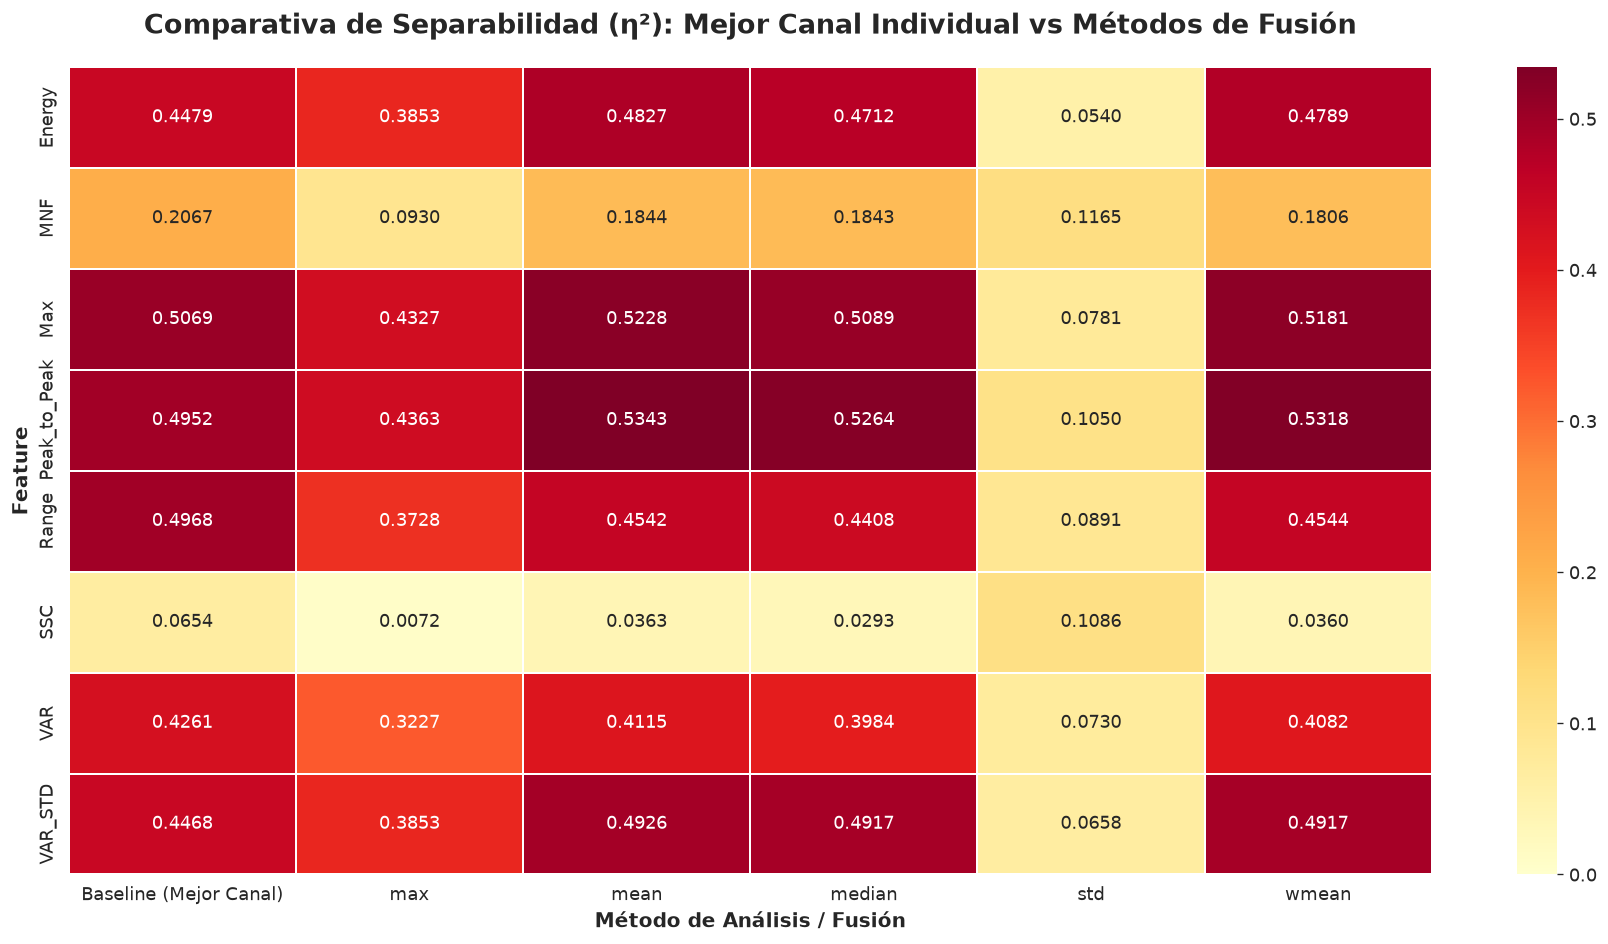

In [8]:
# 1. EXTRACCIÓN SEGURA DEL BASELINE
# Forzamos la creación de un DataFrame con el valor MÁXIMO real por feature
baseline_list = []
for feat in FEATURES:
    # Filtramos todas las filas de esa feature en el baseline
    feat_data = eta2_baseline[eta2_baseline['feature'] == feat]
    # Buscamos el valor máximo de eta2 entre los 8 canales
    max_val = feat_data['eta2'].max() 
    baseline_list.append({'feature': feat, 'method': 'Baseline (Mejor Canal)', 'eta2': max_val})

df_baseline_max = pd.DataFrame(baseline_list)

# 2. Preparar los datos de Fusión (estos ya vienen correctos por feature)
fusion_data = eta2_fusion_norm[['feature', 'method', 'eta2']]

# 3. Unir Baseline + Fusión
df_compare = pd.concat([df_baseline_max, fusion_data], ignore_index=True)

# 4. Pivotar para el Heatmap
pivot_compare = df_compare.pivot(index='feature', columns='method', values='eta2')

# Asegurar que el Baseline esté a la izquierda
cols = ['Baseline (Mejor Canal)'] + [m for m in pivot_compare.columns if m != 'Baseline (Mejor Canal)']
pivot_compare = pivot_compare[cols]

# 5. Visualización
plt.figure(figsize=(15, 8))
sns.heatmap(pivot_compare, 
            annot=True, 
            fmt='.4f', 
            cmap='YlOrRd', 
            linewidths=1, 
            linecolor='white', 
            vmin=0, 
            vmax=pivot_compare.max().max())

plt.title('Comparativa de Separabilidad (η²): Mejor Canal Individual vs Métodos de Fusión', 
          fontweight='bold', fontsize=16, pad=20)
plt.xlabel('Método de Análisis / Fusión', fontweight='bold', fontsize=12)
plt.ylabel('Feature', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

In [9]:
# Tabla resumen: mejor método por feature
best_methods = eta2_fusion_norm.loc[
    eta2_fusion_norm.groupby('feature')['eta2'].idxmax()
][['feature', 'method', 'eta2']].reset_index(drop=True)
best_methods.columns = ['Feature', 'Mejor_método', 'η²']

# Agregar η² del baseline (mejor canal individual)
best_baseline = eta2_baseline.groupby('feature')['eta2'].max().reset_index()
best_baseline.columns = ['Feature', 'η²_baseline']

summary = best_methods.merge(best_baseline, on='Feature')
summary['Mejora_%'] = ((summary['η²'] - summary['η²_baseline']) / summary['η²_baseline'] * 100)
summary = summary.round(4)

print('Tabla resumen — Mejor método por feature:')
print(summary.to_string(index=False))

Tabla resumen — Mejor método por feature:
     Feature Mejor_método     η²  η²_baseline  Mejora_%
      Energy         mean 0.4827       0.4479    7.7534
         MNF         mean 0.1844       0.2067  -10.7829
         Max         mean 0.5228       0.5069    3.1488
Peak_to_Peak         mean 0.5343       0.4952    7.8881
       Range        wmean 0.4544       0.4968   -8.5379
         SSC          std 0.1086       0.0654   65.9904
         VAR         mean 0.4115       0.4261   -3.4254
     VAR_STD         mean 0.4926       0.4468   10.2515


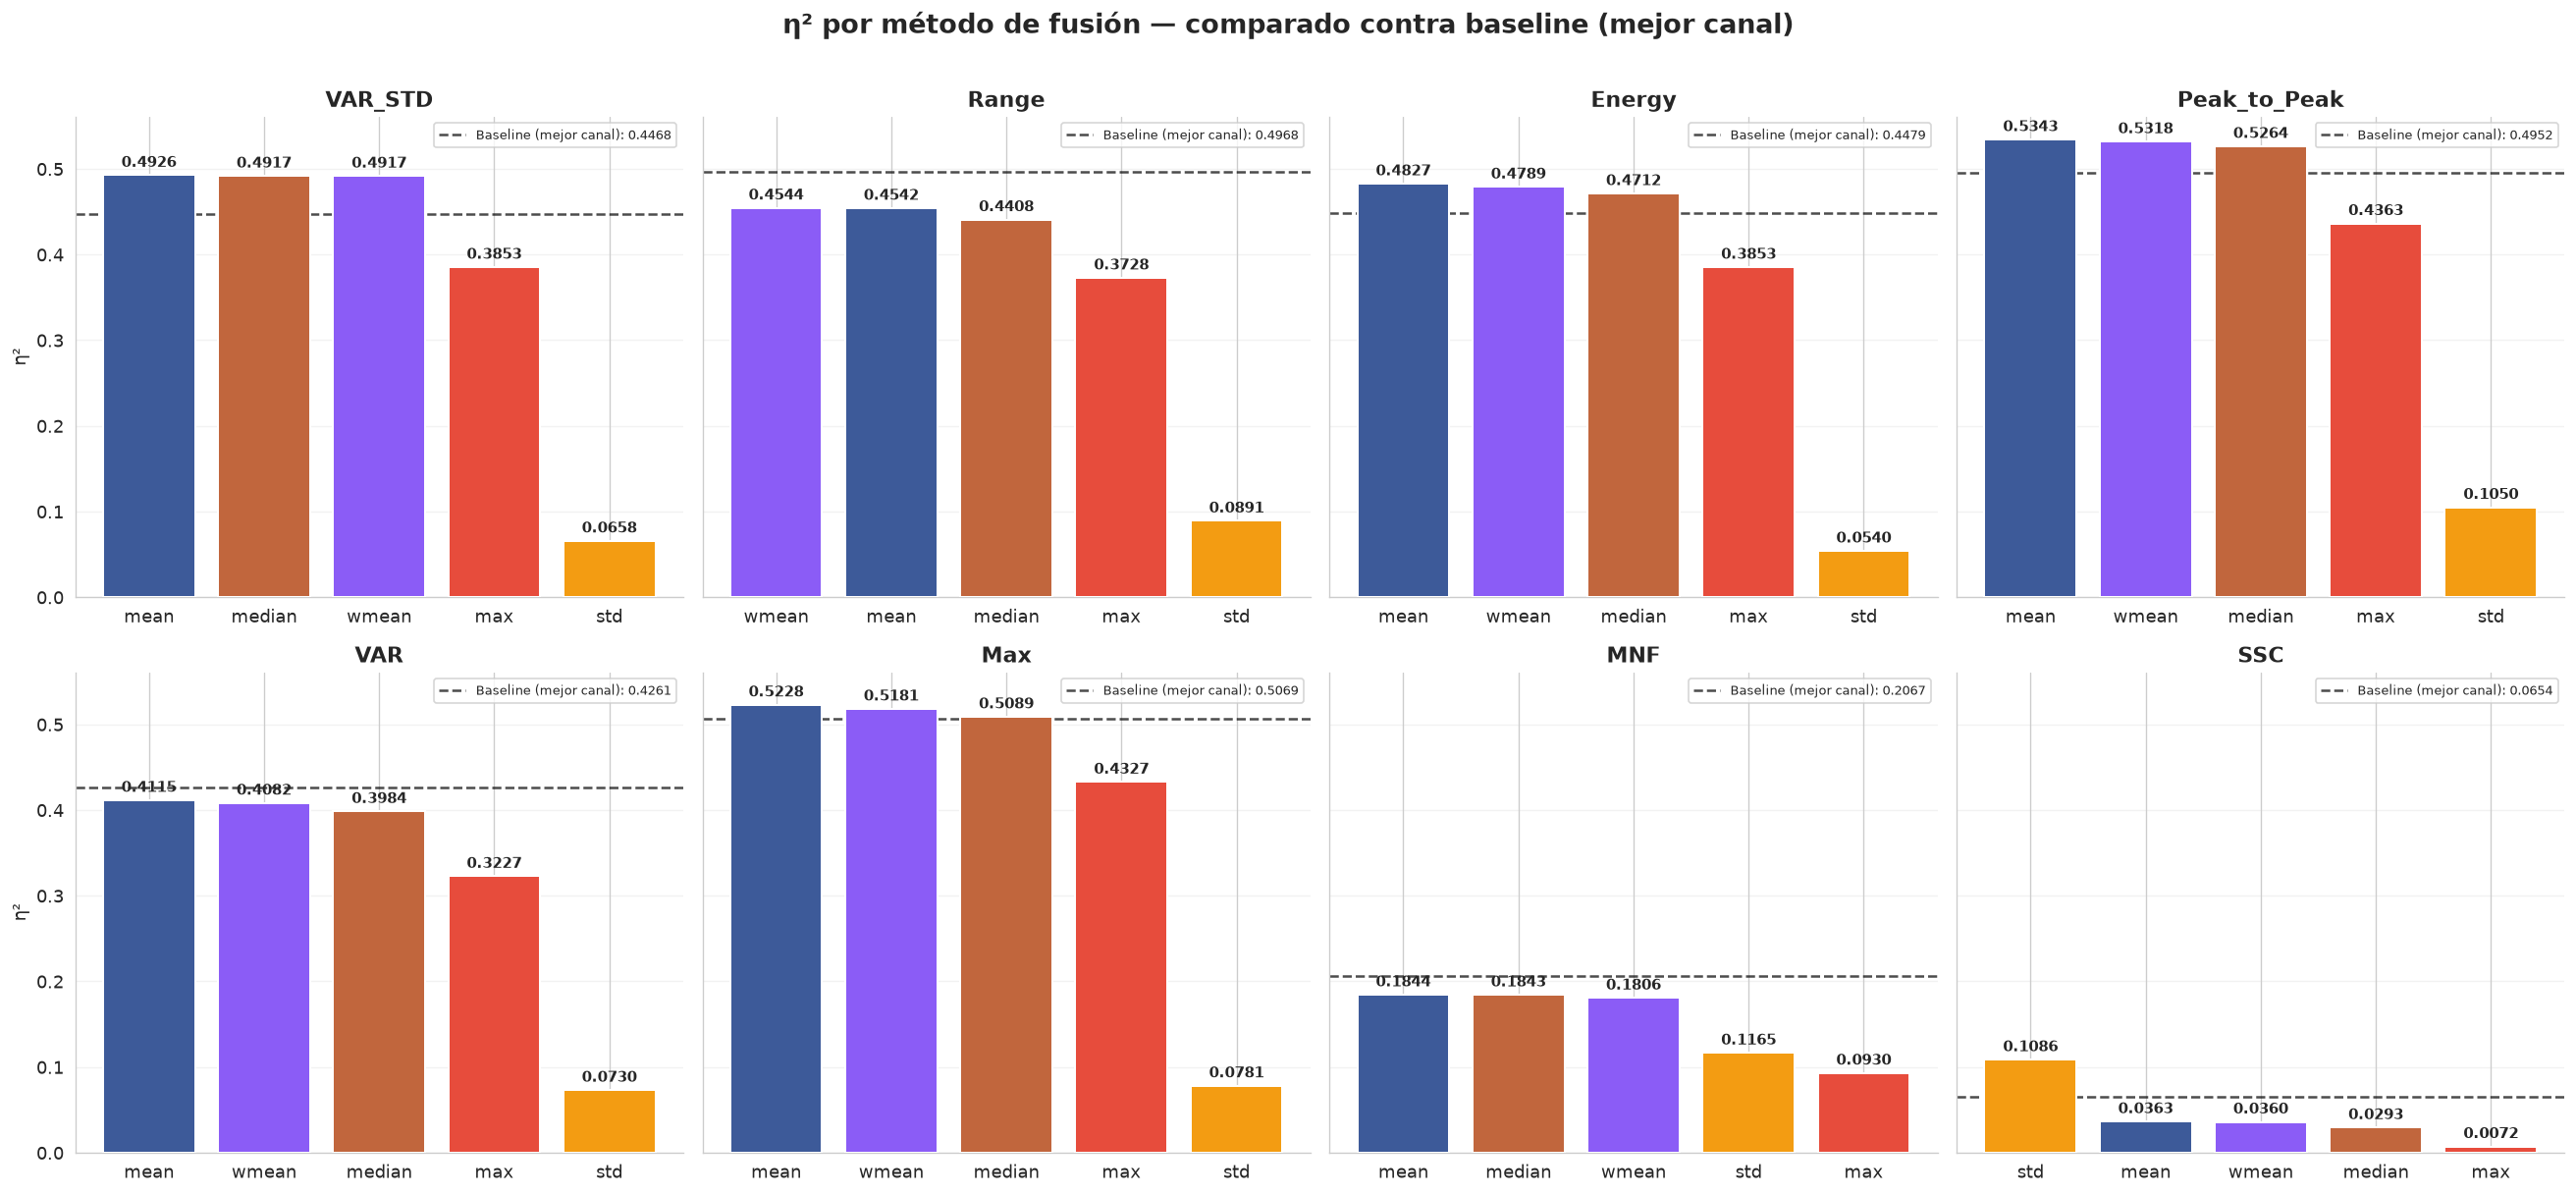

In [10]:
# Barras agrupadas: comparación de los métodos por feature
fig, axes = plt.subplots(2, 4, figsize=(22, 10), sharey=True)
axes = axes.flatten()

colors = {'mean': '#3d5a99', 'median': '#c1663d',
          'wmean': '#8b5cf6', 'max': '#e74c3c', 'std': '#f39c12'}

for i, feat in enumerate(FEATURES):
    ax = axes[i]
    sub = eta2_fusion_norm[eta2_fusion_norm['feature'] == feat].copy()
    sub = sub.sort_values('eta2', ascending=False)
    
    bars = ax.bar(sub['method'], sub['eta2'], color=[colors[m] for m in sub['method']],
                  edgecolor='white', linewidth=1.2, zorder=3)
    ax.bar_label(bars, fmt='%.4f', fontsize=9, fontweight='bold', padding=3)
    
    # Línea del baseline (mejor canal individual)
    bl = eta2_baseline[eta2_baseline['feature'] == feat]['eta2'].max()
    ax.axhline(bl, color='black', ls='--', lw=1.5, alpha=0.7, label=f'Baseline (mejor canal): {bl:.4f}')
    
    ax.set_title(feat, fontweight='bold', fontsize=13)
    ax.set_ylabel('η²' if i % 4 == 0 else '')
    ax.grid(axis='y', alpha=0.25, zorder=0)
    ax.legend(fontsize=8, loc='upper right')
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

fig.suptitle('η² por método de fusión — comparado contra baseline (mejor canal)',
             fontweight='bold', fontsize=16, y=1.01)
fig.tight_layout()
plt.show()

## 6. Construcción del dataset fusionado

In [11]:
# Construir el dataset fusionado con el mejor método por feature
best_method_dict = dict(zip(summary['Feature'], summary['Mejor_método']))
print('Mejores métodos por feature:')
for feat, method in best_method_dict.items():
    print(f'  {feat}: {method}')

# Aplicar fusión
df_fused = df[['origin_db', 'subject', 'stimulus']].copy()
for feat in FEATURES:
    method = best_method_dict[feat]
    df_fused[feat] = fuse_channels(df, feat, method)

print(f'\nShape del dataset fused: {df_fused.shape}')
df_fused.head()

Mejores métodos por feature:
  Energy: mean
  MNF: mean
  Max: mean
  Peak_to_Peak: mean
  Range: wmean
  SSC: std
  VAR: mean
  VAR_STD: mean

Shape del dataset fused: (609, 11)


,origin_db,subject,stimulus,VAR_STD,Range,Energy,Peak_to_Peak,VAR,Max,MNF,SSC
1,NinaProDB1,1,22,-0.354087,-0.252804,-0.508157,-0.254103,-0.276010,-0.401212,-0.290107,0.389524
2,NinaProDB1,1,25,-0.284824,0.119208,-0.205256,-0.511692,0.103870,-0.342554,-0.557781,0.534827
3,NinaProDB1,1,27,-0.176866,-0.204332,-0.301253,-0.109957,-0.212648,-0.304009,-0.214540,0.253255
4,NinaProDB1,1,30,0.534995,0.525830,0.405533,0.338493,0.692393,0.277150,-0.319050,0.251775
5,NinaProDB1,1,31,-1.263845,-1.292252,-1.449631,-1.228277,-1.237071,-1.416424,-0.055643,0.631464


In [ ]:
# Guardar
df_fused.to_csv('../data/master/intact_bc_fused.csv', index=False)

Dataset fused guardado en: data/master/intact_boxcox_fused.csv


## 7. Verificación final

In [13]:
# Verificar η² del dataset fused

eta2_fused = []
for feat in FEATURES:
    col = feat
    groups = [x[col].dropna().values for _, x in df_fused.groupby('stimulus')]
    eta2 = separability_eta2(groups)
    eta2_fused.append({'feature': feat, 'η²_fused': eta2})

eta2_fused_df = pd.DataFrame(eta2_fused)

# Comparar con el mejor η² de fusión (de la tabla resumen)
comparison = summary[['Feature', 'η²', 'Mejor_método']].merge(eta2_fused_df, left_on='Feature', right_on='feature')
comparison = comparison[['Feature', 'Mejor_método', 'η²', 'η²_fused']]
comparison.columns = ['Feature', 'Método', 'η² teórico', 'η² verificado']
print('Verificación del dataset fused:')
print(comparison.round(4).to_string(index=False))

Verificación del dataset fused:
     Feature Método  η² teórico  η² verificado
      Energy   mean      0.4827         0.4827
         MNF   mean      0.1844         0.1844
         Max   mean      0.5228         0.5228
Peak_to_Peak   mean      0.5343         0.5343
       Range  wmean      0.4544         0.4544
         SSC    std      0.1086         0.1086
         VAR   mean      0.4115         0.4115
     VAR_STD   mean      0.4926         0.4926


In [14]:
def plot_fused_stimulus_boxplots(
    df,
    features,
    eta2_df=None,
    stimulus_col='stimulus',
    ylabel='Z-score',
    title='Distribuciones fused por estímulo — dataset final',
    palette='Set2',
    figsize=(22, 10),
    show=True,
    save_path=None,
):
    """
    Grid de boxplots: cada feature × estímulo.

    Parámetros
    ----------
    df        : DataFrame con columnas de features y stimulus_col
    features  : lista de nombres de columnas a graficar
    eta2_df   : DataFrame opcional con columnas ['feature', 'η²_fused']
                para anotar el η² en cada título
    save_path : str opcional ('.png'/'.pdf') para guardar la figura

    Retorna
    -------
    (fig, axes)
    """
    n = len(features)
    ncols = min(4, n)
    nrows = -(-n // ncols)  # ceil

    # Mapa feature → η² (si se proporcionó)
    eta2_map = {}
    if eta2_df is not None and len(eta2_df) > 0:
        eta2_map = dict(zip(eta2_df['feature'], eta2_df['η²_fused']))

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharey=True)
    axes = np.atleast_1d(axes).flatten()

    for i, feat in enumerate(features):
        ax = axes[i]
        sns.boxplot(
            data=df, x=stimulus_col, y=feat, ax=ax,
            hue=stimulus_col, palette=palette, legend=False,
            showfliers=False, width=0.7,
            medianprops=dict(color='black', linewidth=1.5),
        )

        if feat in eta2_map and pd.notna(eta2_map[feat]):
            ax.set_title(f'{feat} (η²={eta2_map[feat]:.4f})',
                         fontweight='bold', fontsize=12)
        else:
            ax.set_title(feat, fontweight='bold', fontsize=12)

        ax.set_xlabel('Estímulo' if i >= ncols else '')
        ax.set_ylabel(ylabel if i % ncols == 0 else '')
        ax.grid(axis='y', alpha=0.25)
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)

    # Apagar ejes sobrantes
    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle(title, fontweight='bold', fontsize=16, y=1.01)
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
    if show:
        plt.show()

    return fig, axes

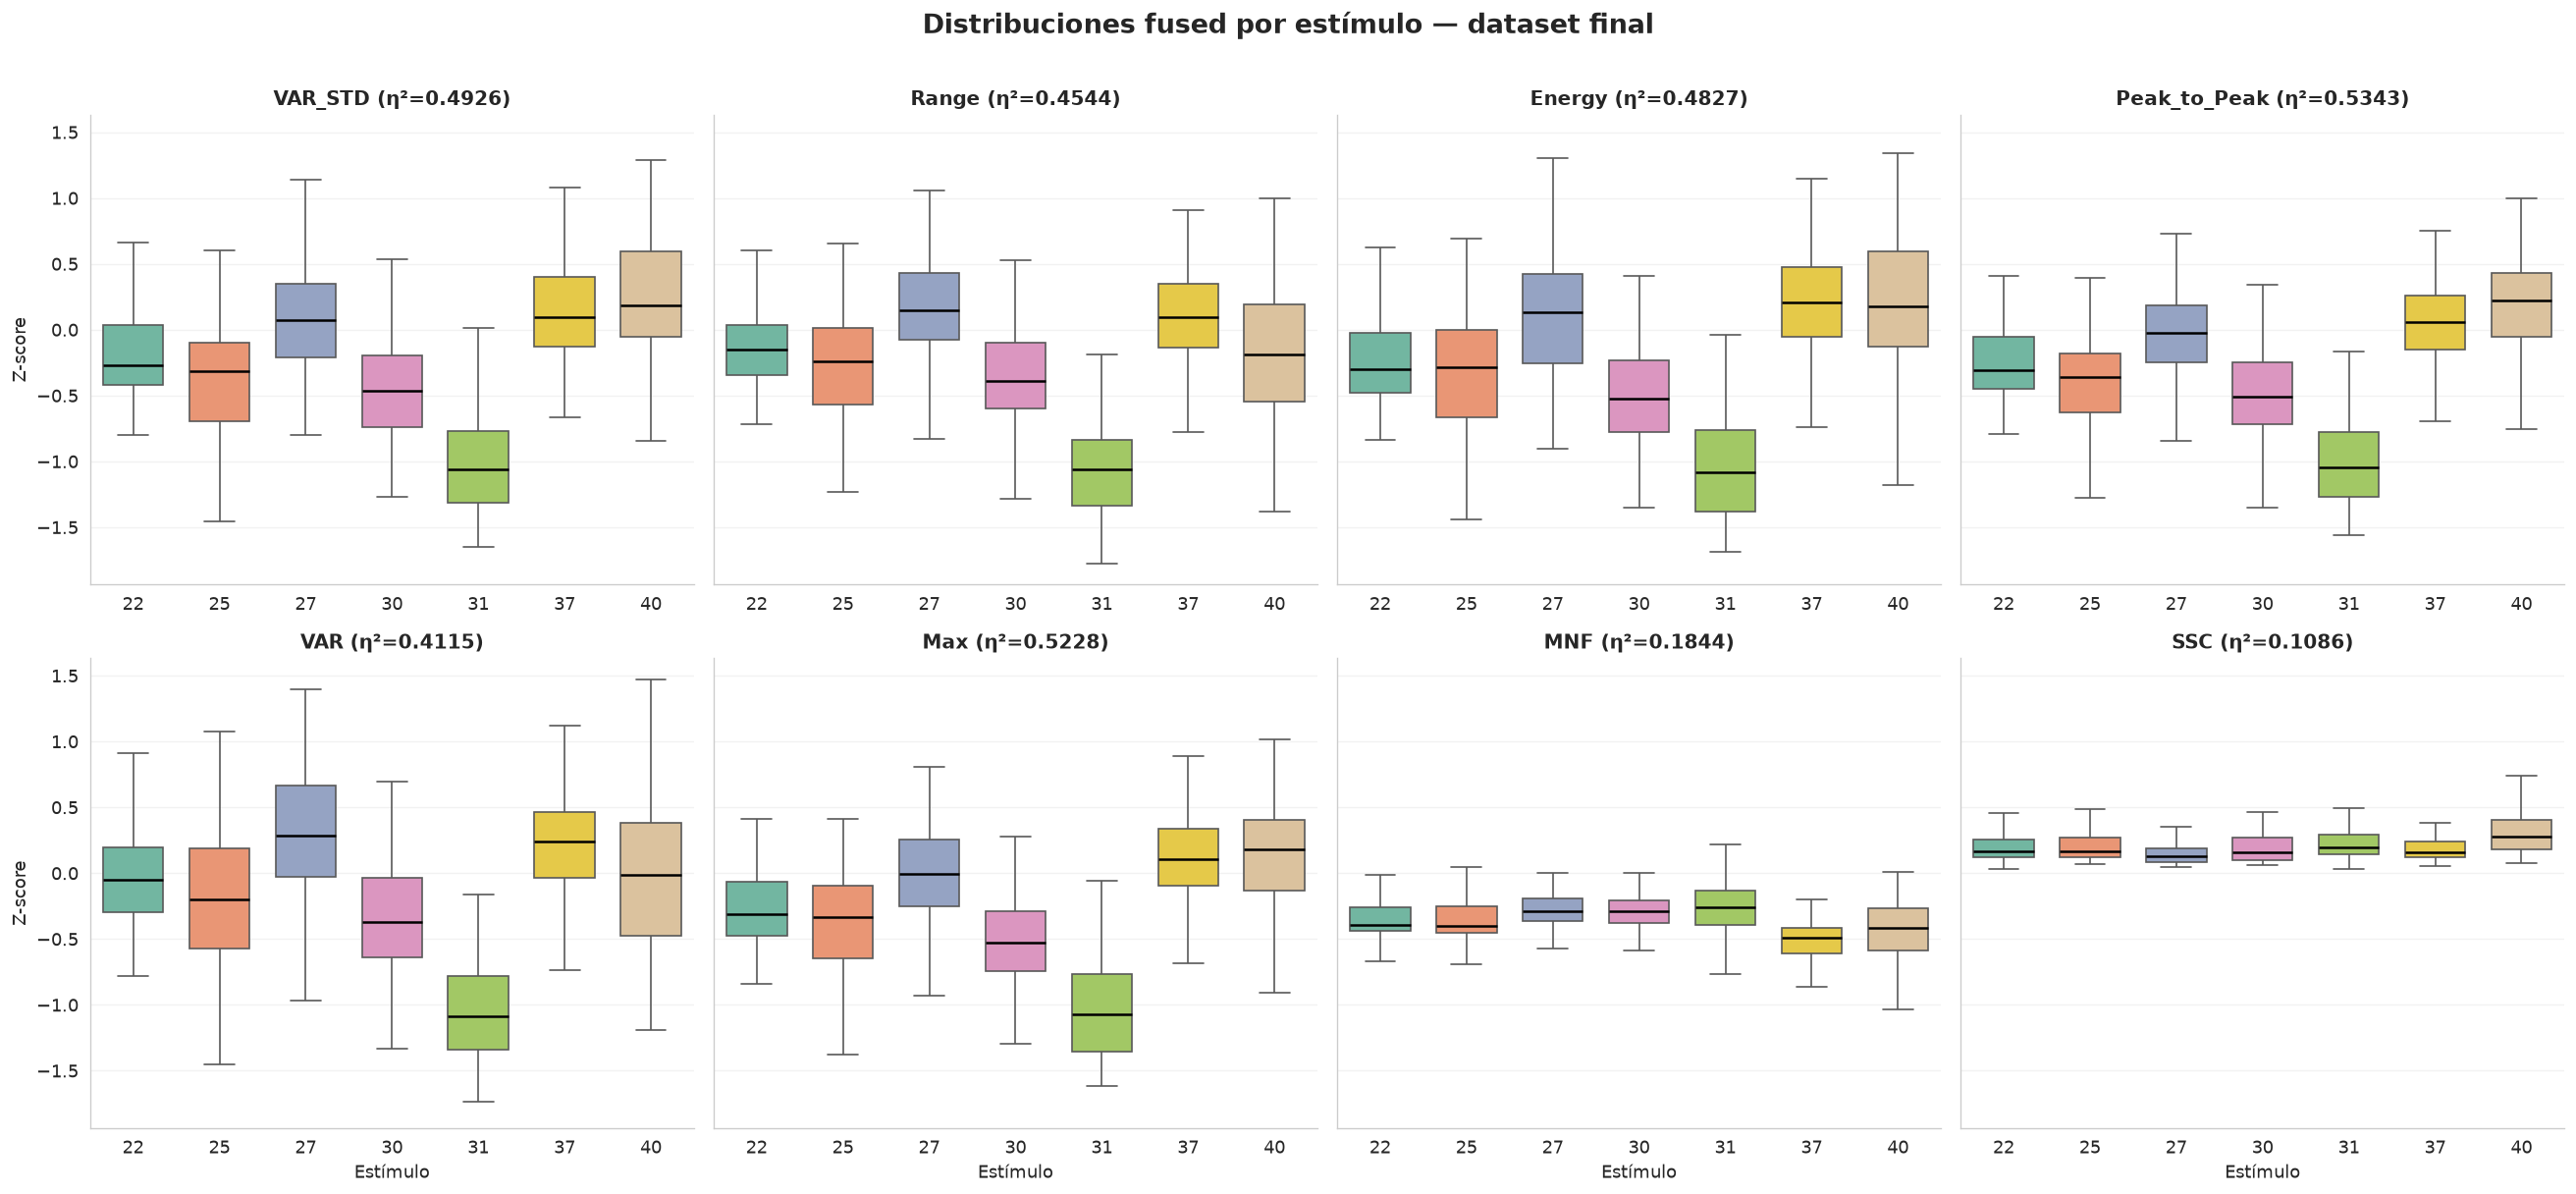

In [15]:
fig, axes = plot_fused_stimulus_boxplots(df_fused, FEATURES, eta2_fused_df)

In [16]:
# Silhouette score global del dataset fused
from sklearn.metrics import silhouette_score

X_fused = df_fused[FEATURES].values
labels = df_fused['stimulus'].values

# Filtrar NaN
mask = ~np.isnan(X_fused).any(axis=1)
sil = silhouette_score(X_fused[mask], labels[mask])
print(f'Silhouette score del dataset fused: {sil:.4f}')

# Comparar con el dataset original (mejores canales)
best_channel_cols = []
for feat in FEATURES:
    best_ch = eta2_baseline[eta2_baseline['feature'] == feat].sort_values('eta2', ascending=False).iloc[0]['channel']
    best_channel_cols.append(f'Channel {int(best_ch)}_{feat}')

X_best = df[best_channel_cols].values
mask2 = ~np.isnan(X_best).any(axis=1)
sil_baseline = silhouette_score(X_best[mask2], labels[mask2])
print(f'Silhouette score baseline (mejores canales individuales): {sil_baseline:.4f}')

Silhouette score del dataset fused: -0.0783
Silhouette score baseline (mejores canales individuales): -0.0608


In [17]:
def plot_kde_grid(df, features, stimulus_col='stimulus', 
                  prefix='', palette='Set2', figsize=(20, 10)):
    """
    Grid 2×4 con KDE de cada feature por estímulo.
    Leyenda compartida centrada arriba de la figura.
    """
    stimuli = sorted(df[stimulus_col].unique())
    colors = sns.color_palette(palette, n_colors=len(stimuli))
    color_map = dict(zip(stimuli, colors))
    
    fig, axes = plt.subplots(2, 4, figsize=figsize)
    axes = axes.flatten()
    
    for i, feat in enumerate(features):
        ax = axes[i]
        col = f'{prefix}{feat}'
        for stim in stimuli:
            subset = df.loc[df[stimulus_col] == stim, col].dropna()
            subset.plot.kde(ax=ax, color=color_map[stim], linewidth=2)
        
        ax.set_title(feat, fontweight='bold', fontsize=13)
        ax.set_xlabel('')
        ax.set_ylabel('Densidad' if i % 4 == 0 else '')
        ax.grid(alpha=0.25)
        ax.set_xlim(ax.get_xlim())  # fijar límites para consistencia
        for s in ('top', 'right'):
            ax.spines[s].set_visible(False)
    
    # Leyenda centrada arriba
    handles = [Patch(facecolor=color_map[s], label=f'Stimulus {s}') for s in stimuli]
    fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 1.02),
               ncol=len(stimuli), fontsize=12, frameon=False, title='Estímulo')
    
    fig.suptitle('Distribución KDE por estímulo — Features fused', 
                 fontweight='bold', fontsize=16, y=1.06)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

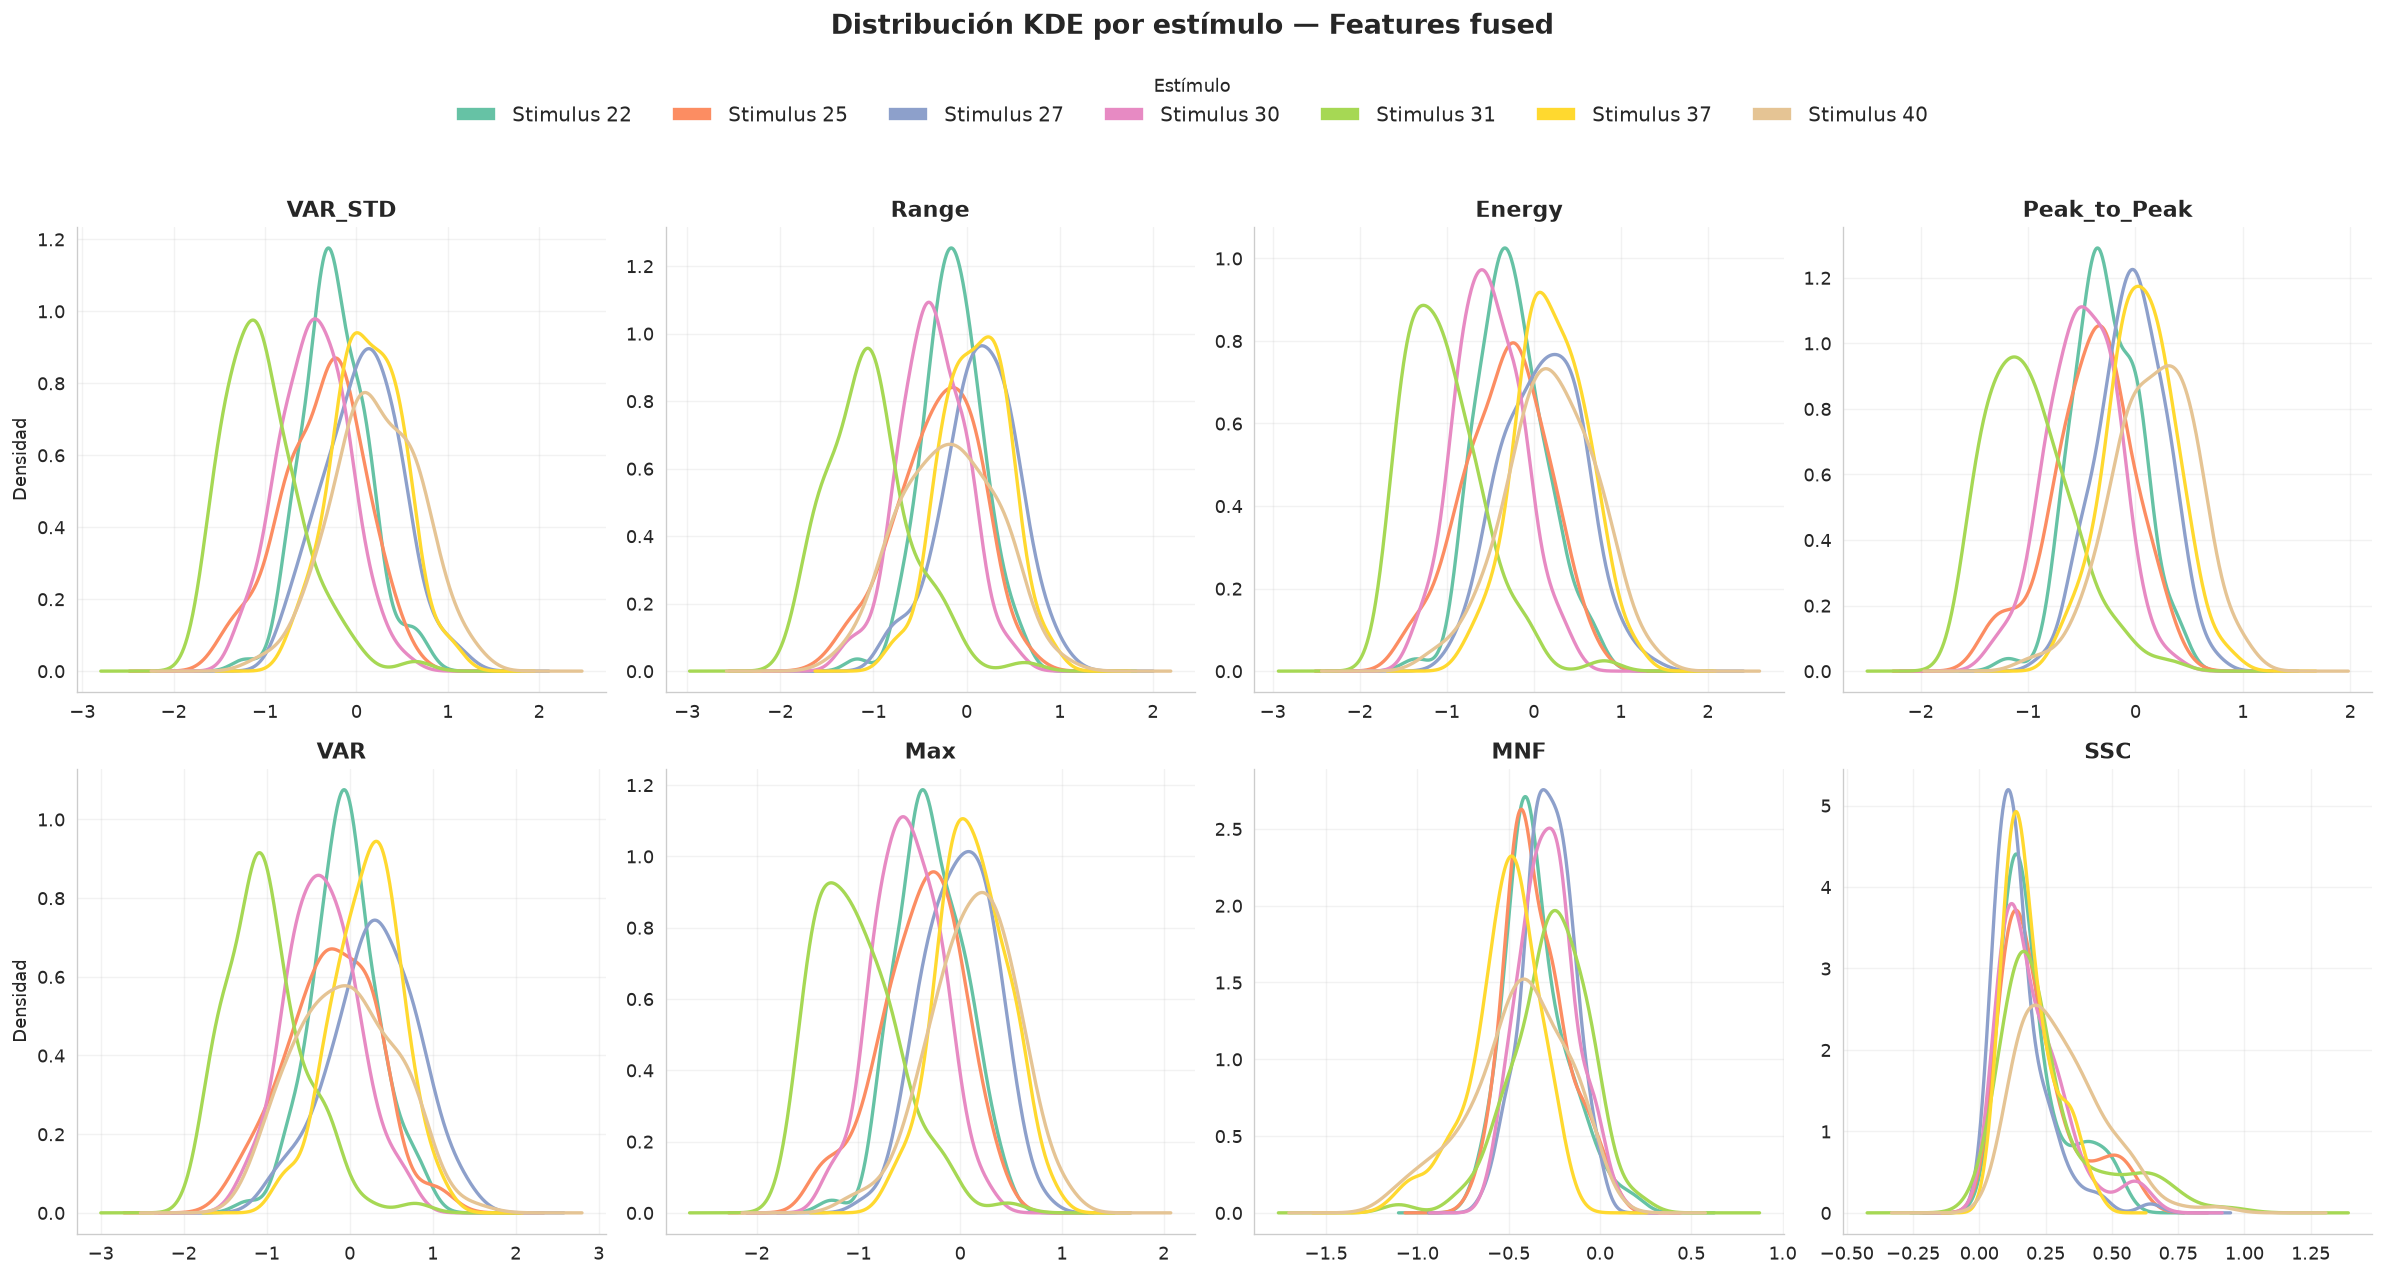

In [18]:
plot_kde_grid(df_fused, FEATURES)